# House-value regression in Python

Topic 8 · Dimensionality reduction and feature selection

The goal is to predict `MEDV` from the 13 supplied numerical predictors and measure how much predictive quality is retained when fewer inputs are passed to a Random Forest. The supplied Topic 8 notebooks inform the workflow. This analysis uses regression models, continuous target colours and regression metrics.

Run all cells with a Python 3 kernel and keep `house_data.csv` in the notebook working directory. The analysis uses NumPy, pandas, Matplotlib, scikit-learn and umap-learn. Package versions are listed in Section 10.

## 1. Load, inspect, and document the data

The local CSV contains one record per observation. `MEDV` is a continuous house-value target. All other columns are treated as numerical inputs. Keep unusual observations, including values at the upper end of the observed target range.

In [1]:
from importlib.metadata import version
from pathlib import Path
import platform
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso
from sklearn.manifold import TSNE
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from umap import UMAP

seed = 42
target = "MEDV"
raw = pd.read_csv(Path("house_data.csv"))
assert target in raw and raw.select_dtypes("number").shape[1] == raw.shape[1]

features = raw.columns.drop(target)
duplicates = int(raw.duplicated().sum())
constants = raw[features].nunique().loc[lambda n: n <= 1].index
data = raw.drop_duplicates().reset_index(drop=True)
assert data[target].notna().all(), "MEDV must be observed for regression."

print(f"Original dimensions: {raw.shape[0]} rows x {raw.shape[1]} columns")
display(raw.head().round(4))
display(pd.DataFrame({"Type": raw.dtypes.astype(str), "Missing": raw.isna().sum()}))
display(pd.Series({
    "Original rows": len(raw),
    "Final rows": len(data),
    "Predictors": len(features),
    "Missing predictor values": int(raw[features].isna().sum().sum()),
    "Missing target values": int(raw[target].isna().sum()),
    "Exact duplicate rows removed": duplicates,
    "Constant predictors": len(constants),
}, name="Count").to_frame())
print("Constant predictor names:", ", ".join(constants) or "None")

Original dimensions: 506 rows x 14 columns


,CRIM,ZN,INDUS,CHAS,NX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.0063,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.0273,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.0273,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.0324,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.0690,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


,Type,Missing
CRIM,float64,0
ZN,float64,0
INDUS,float64,0
CHAS,int64,0
NX,float64,0
RM,float64,0
AGE,float64,0
DIS,float64,0
RAD,int64,0
TAX,float64,0


,Count
Original rows,506
Final rows,506
Predictors,13
Missing predictor values,0
Missing target values,0
Exact duplicate rows removed,0
Constant predictors,0


Constant predictor names: None


## 2. Fix the split and prevent data leakage

Use one random 80/20 split with seed 42. Estimate medians and scaling parameters on the training predictors and apply those parameters to both partitions. All reduction decisions use the training partition. Test metrics are computed together in Section 7 after all settings are fixed.

In [2]:
X, y = data[features], data[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=seed
)
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
train_imputed = imputer.fit_transform(X_train)
test_imputed = imputer.transform(X_test)
train_scaled = scaler.fit_transform(train_imputed)
test_scaled = scaler.transform(test_imputed)

assert target not in X_train.columns
assert X_train.index.intersection(X_test.index).empty
print(f"Split seed: {seed}")
print(f"Training: {len(y_train)} rows | Test: {len(y_test)} rows")

Split seed: 42
Training: 404 rows | Test: 102 rows


## 3. Establish the Random Forest baseline

Use all 13 prepared predictors. Every forest uses 300 bootstrap trees, seed 42, and considers all available inputs at each split. Use one worker for timing. The implementation defaults include squared-error splits, no depth limit, at least two samples to split a node, one sample per leaf, and a bootstrap sample of training-set size. Only the call to fit the forest is timed.

,mean,std,min,50%,max
CRIM,3.609,8.875,0.009,0.261,88.976
ZN,11.569,23.152,0.000,0.000,100.000
INDUS,10.985,6.895,0.740,8.560,27.740
CHAS,0.072,0.258,0.000,0.000,1.000
NX,0.556,0.118,0.385,0.538,0.871
RM,6.316,0.709,3.863,6.210,8.780
AGE,68.556,27.995,2.900,77.700,100.000
DIS,3.808,2.131,1.130,3.176,12.126
RAD,9.356,8.590,1.000,5.000,24.000
TAX,404.032,166.173,187.000,330.000,711.000


,MEDV
count,404.000
mean,22.797
std,9.332
min,5.000
25%,16.950
50%,21.600
75%,26.400
max,50.000


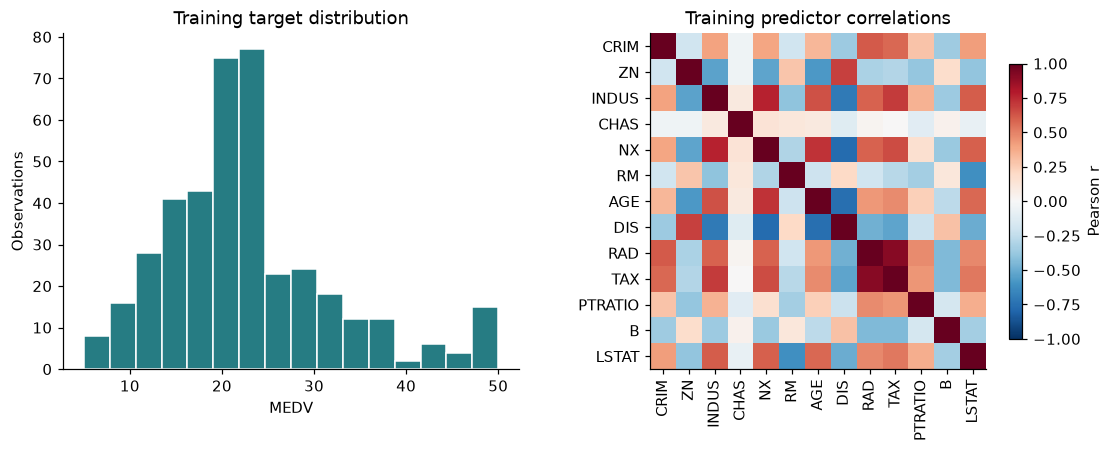

In [3]:
summary = pd.DataFrame(train_imputed, columns=features).describe().T
display(summary[["mean", "std", "min", "50%", "max"]].round(3))
display(y_train.describe().round(3).to_frame())

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
corr = pd.DataFrame(train_imputed, columns=features).corr()
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].hist(y_train, bins=16, color="#267c83", edgecolor="white")
axes[0].set(title="Training target distribution", xlabel="MEDV",
            ylabel="Observations")
image = axes[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set(xticks=range(len(features)), yticks=range(len(features)),
            yticklabels=features, title="Training predictor correlations")
axes[1].set_xticklabels(features, rotation=90)
fig.colorbar(image, ax=axes[1], label="Pearson r", shrink=0.82)
plt.show()

In [4]:
def fit_forest(train_matrix):
    forest = RandomForestRegressor(
        n_estimators=300, max_features=1.0, bootstrap=True,
        random_state=seed, n_jobs=1
    )
    start = perf_counter()
    forest.fit(train_matrix, y_train)
    return forest, perf_counter() - start

baseline_fit = fit_forest(train_scaled)
print(f"Baseline Random Forest fit: {baseline_fit[1]:.3f} s")

Baseline Random Forest fit: 0.809 s


## 4. Apply PCA before Random Forest

Use full SVD on the standardised training predictors. A 90% training variance target keeps most observed predictor variation while allowing compression. The first component count to reach the threshold determines the forest inputs. Explained variance measures variation in the predictors.

,Component,Explained (%),Cumulative (%)
0,1,46.37,46.37
1,2,11.40,57.77
2,3,9.78,67.54
3,4,6.70,74.25
4,5,6.54,80.78
5,6,5.12,85.90
6,7,4.11,90.01
7,8,3.04,93.05
8,9,2.08,95.14
9,10,1.70,96.84


Threshold: 90% | Retained: 7 | Retained variance: 90.01%


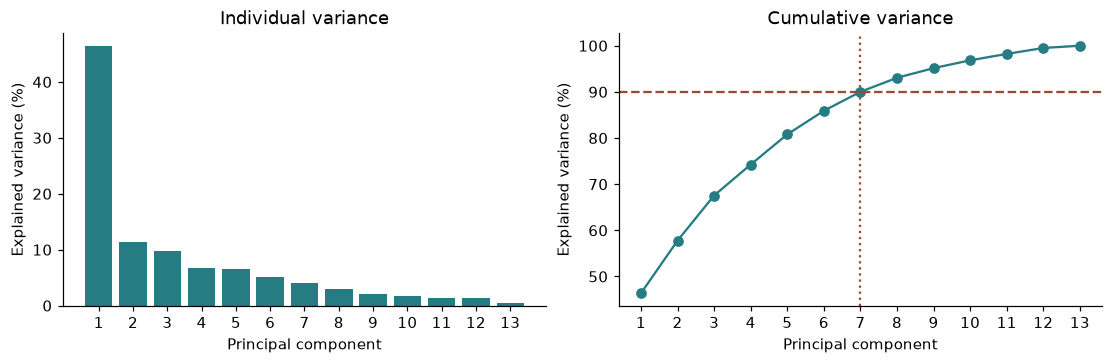

In [5]:
pca = PCA(svd_solver="full")
train_scores = pca.fit_transform(train_scaled)
test_scores = pca.transform(test_scaled)
variance = pca.explained_variance_ratio_
cumulative = variance.cumsum()
components = np.arange(1, len(variance) + 1)
threshold = 0.90
k = int(np.searchsorted(cumulative, threshold) + 1)

display(pd.DataFrame({
    "Component": components,
    "Explained (%)": 100 * variance,
    "Cumulative (%)": 100 * cumulative,
}).round(2))
print(f"Threshold: {threshold:.0%} | Retained: {k} | "
      f"Retained variance: {cumulative[k - 1]:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
axes[0].bar(components, 100 * variance, color="#267c83")
axes[0].set(title="Individual variance", ylabel="Explained variance (%)")
axes[1].plot(components, 100 * cumulative, "o-", color="#267c83")
axes[1].axhline(100 * threshold, linestyle="--", color="#9b4b31")
axes[1].axvline(k, linestyle=":", color="#9b4b31")
axes[1].set(title="Cumulative variance", ylabel="Explained variance (%)")
for ax in axes:
    ax.set(xlabel="Principal component", xticks=components)
plt.show()

pca_fit = fit_forest(train_scores[:, :k])

## 5. Apply Lasso selection before Random Forest

Inspect manually listed penalty strengths and their training coefficients. Use the weakest listed strength that removes at least three inputs while retaining at least one. This gives a concrete compression target without consulting test scores. A predictor is active when its absolute coefficient exceeds 1e-6. The intercept is excluded.

,0.03,0.10,0.20,0.35,0.55,0.80,1.20
CRIM,-0.9198,-0.7183,-0.4932,-0.4060,-0.2658,-0.1092,-0.0000
ZN,0.5479,0.2590,0.0000,0.0000,0.0000,0.0000,0.0000
INDUS,0.0060,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000
CHAS,0.7227,0.6982,0.6376,0.5129,0.3793,0.2055,0.0000
NX,-1.8343,-1.5678,-1.0532,-0.4298,-0.0000,-0.0000,-0.0000
RM,3.1635,3.2716,3.3623,3.3484,3.3108,3.1956,2.9579
AGE,-0.1076,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000
DIS,-2.8720,-2.2836,-1.6181,-0.9177,-0.2243,-0.0000,-0.0000
RAD,1.7156,0.6713,0.0000,-0.0000,-0.0000,-0.0000,-0.0000
TAX,-1.2317,-0.3560,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000


Chosen Lasso alpha: 0.2 | Retained: 8
Selected predictors: CRIM, CHAS, NX, RM, DIS, PTRATIO, B, LSTAT


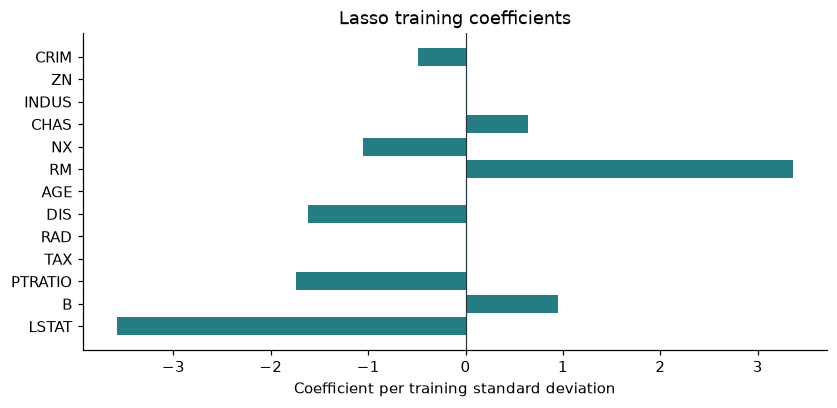

In [6]:
penalties = [0.03, 0.10, 0.20, 0.35, 0.55, 0.80, 1.20]
cutoff = 1e-6

def inspect_penalties(make_selector):
    coefficients = {}
    for penalty in penalties:
        selector = make_selector(penalty)
        selector.fit(train_scaled, y_train)
        coefficients[penalty] = selector.coef_
    trial = pd.DataFrame(coefficients, index=features)
    active = trial.abs().gt(cutoff)
    counts = active.sum()
    display(pd.concat([trial, counts.to_frame().T.set_axis(["Retained"])]).round(4))
    chosen = counts.loc[counts.between(1, len(features) - 3)].index[0]
    return chosen, trial[chosen], active[chosen].to_numpy()

def plot_coefficients(coefficients, selected, name):
    fig, ax = plt.subplots(figsize=(7.5, 3.6), layout="constrained")
    ax.barh(coefficients.index, coefficients,
            color=np.where(selected, "#267c83", "#bec7cc"))
    ax.axvline(0, color="#26343d", linewidth=0.8)
    ax.invert_yaxis()
    ax.set(title=f"{name} training coefficients",
           xlabel="Coefficient per training standard deviation")
    plt.show()

lasso_penalty, lasso_coef, lasso_mask = inspect_penalties(
    lambda penalty: Lasso(alpha=penalty, max_iter=50_000, tol=1e-8)
)
lasso_features = features[lasso_mask]
print(f"Chosen Lasso alpha: {lasso_penalty} | Retained: {len(lasso_features)}")
print("Selected predictors:", ", ".join(lasso_features))
plot_coefficients(lasso_coef, lasso_mask, "Lasso")
lasso_fit = fit_forest(train_scaled[:, lasso_mask])

## 6. Apply Elastic Net selection before Random Forest

Fix the L1 mixing ratio at 0.5 to combine sparsity with L2 shrinkage. Inspect the same penalty candidates and apply the same training-only retention rule. This is a separate selector fit using the original standardised predictors.

,0.03,0.10,0.20,0.35,0.55,0.80,1.20
CRIM,-0.9125,-0.7616,-0.6248,-0.5346,-0.4875,-0.4408,-0.3875
ZN,0.5356,0.3228,0.1475,0.0072,0.0000,0.0000,0.0000
INDUS,0.0285,-0.0317,-0.1242,-0.1615,-0.1706,-0.1789,-0.2245
CHAS,0.7375,0.7369,0.7208,0.6749,0.6067,0.5256,0.3986
NX,-1.7620,-1.3961,-1.0278,-0.7098,-0.4689,-0.3021,-0.2199
RM,3.1809,3.2332,3.2170,3.1134,2.9323,2.7134,2.3944
AGE,-0.1481,-0.0957,-0.0295,-0.0000,-0.0000,-0.0000,-0.0000
DIS,-2.7784,-2.1766,-1.5966,-1.0338,-0.5908,-0.2137,-0.0000
RAD,1.6322,0.8475,0.2383,0.0000,-0.0000,-0.0000,-0.0000
TAX,-1.1960,-0.6244,-0.2494,-0.1836,-0.2688,-0.3182,-0.3508


Chosen Elastic Net alpha: 0.55 | L1 ratio: 0.5 | Retained: 10
Selected predictors: CRIM, INDUS, CHAS, NX, RM, DIS, TAX, PTRATIO, B, LSTAT


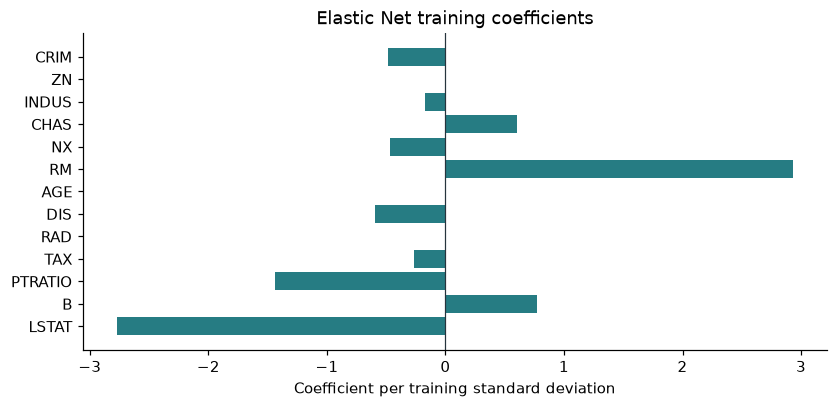

Shared: CRIM, CHAS, NX, RM, DIS, PTRATIO, B, LSTAT
Lasso only: None
Elastic Net only: INDUS, TAX


,CRIM,CHAS,NX,RM,DIS,PTRATIO,B,LSTAT
INDUS,0.40,0.10,0.77,-0.40,-0.71,0.35,-0.36,0.60
TAX,0.58,0.01,0.65,-0.28,-0.52,0.44,-0.44,0.53


In [7]:
mixing = 0.5
en_penalty, en_coef, en_mask = inspect_penalties(
    lambda penalty: ElasticNet(
        alpha=penalty, l1_ratio=mixing, max_iter=50_000, tol=1e-8
    )
)
en_features = features[en_mask]
print(f"Chosen Elastic Net alpha: {en_penalty} | L1 ratio: {mixing} | "
      f"Retained: {len(en_features)}")
print("Selected predictors:", ", ".join(en_features))
plot_coefficients(en_coef, en_mask, "Elastic Net")
en_fit = fit_forest(train_scaled[:, en_mask])

shared = lasso_features.intersection(en_features)
lasso_only = lasso_features.difference(en_features)
en_only = en_features.difference(lasso_features)
different = lasso_only.union(en_only)
print("Shared:", ", ".join(shared) or "None")
print("Lasso only:", ", ".join(lasso_only) or "None")
print("Elastic Net only:", ", ".join(en_only) or "None")
display(corr.loc[different, shared].round(2))

## 7. Compare all four pipelines on the test set

RMSE and MAE are in MEDV units. R² is computed against the mean of the held-out observations. All panels use the same observations and axis limits. The dashed diagonal represents perfect agreement. Times measure a single one-worker fit and can vary across runs.

,Inputs,RMSE,MAE,R2,RF fit time (s)
Pipeline,,,,,
Baseline,13,3.0052,2.0822,0.8768,0.8090
PCA + RF,7,4.2549,2.4782,0.7531,0.7852
Lasso + RF,8,3.0768,2.1343,0.8709,0.8408
Elastic Net + RF,10,3.0290,2.1111,0.8749,1.0322


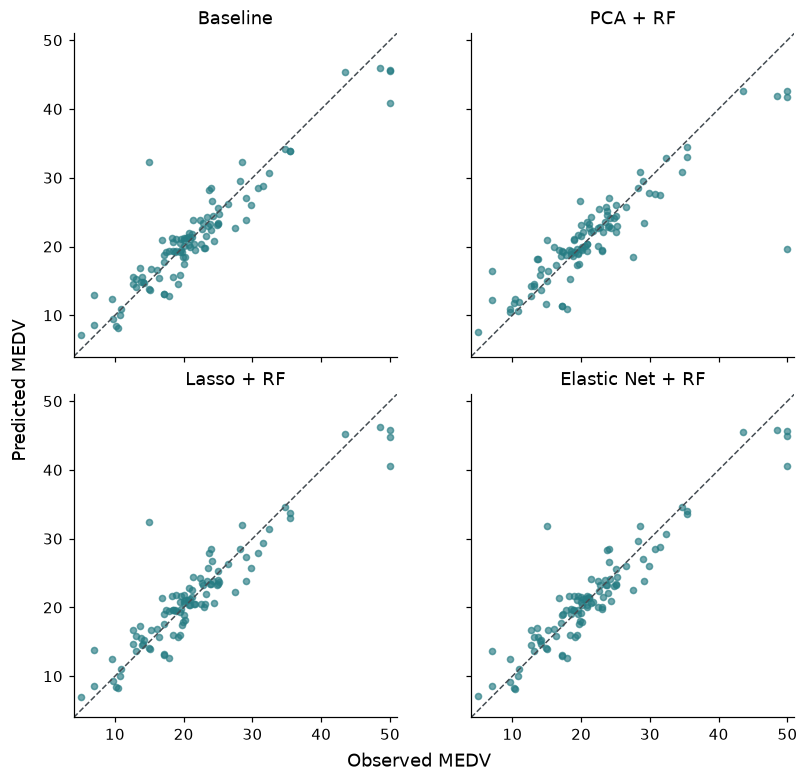

In [8]:
pipelines = {
    "Baseline": (baseline_fit, test_scaled),
    "PCA + RF": (pca_fit, test_scores[:, :k]),
    "Lasso + RF": (lasso_fit, test_scaled[:, lasso_mask]),
    "Elastic Net + RF": (en_fit, test_scaled[:, en_mask]),
}
predictions = {}
rows = []
for name, ((forest, fit_time), test_matrix) in pipelines.items():
    predicted = forest.predict(test_matrix)
    predictions[name] = predicted
    rows.append({
        "Pipeline": name,
        "Inputs": test_matrix.shape[1],
        "RMSE": np.sqrt(mean_squared_error(y_test, predicted)),
        "MAE": mean_absolute_error(y_test, predicted),
        "R2": r2_score(y_test, predicted),
        "RF fit time (s)": fit_time,
    })
results = pd.DataFrame(rows).set_index("Pipeline")
display(results.round(4))

values = np.concatenate([y_test.to_numpy(), *predictions.values()])
limits = (values.min() - 1, values.max() + 1)
fig, axes = plt.subplots(2, 2, figsize=(7.5, 7),
                         sharex=True, sharey=True, layout="constrained")
for ax, (name, predicted) in zip(axes.flat, predictions.items()):
    ax.scatter(y_test, predicted, s=16, alpha=0.65, color="#267c83")
    ax.plot(limits, limits, "--", color="#454d53", linewidth=1)
    ax.set(xlim=limits, ylim=limits, title=name, aspect="equal")
fig.supxlabel("Observed MEDV")
fig.supylabel("Predicted MEDV")
plt.show()

## 8. Visualise PCA and t-SNE

Embed the same standardised training rows each time. Use `MEDV` only to colour points after fitting. All embedding plots share the Viridis scale over the training target range. Use Euclidean t-SNE with random initialisation, learning rate 200, early exaggeration 12, Barnes-Hut angle 0.5, and up to 1,000 iterations. Reuse the perplexity-30, seed-42 result in the seed comparison.

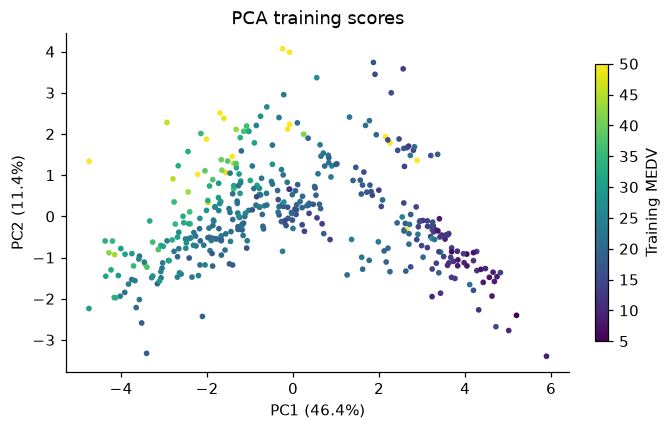

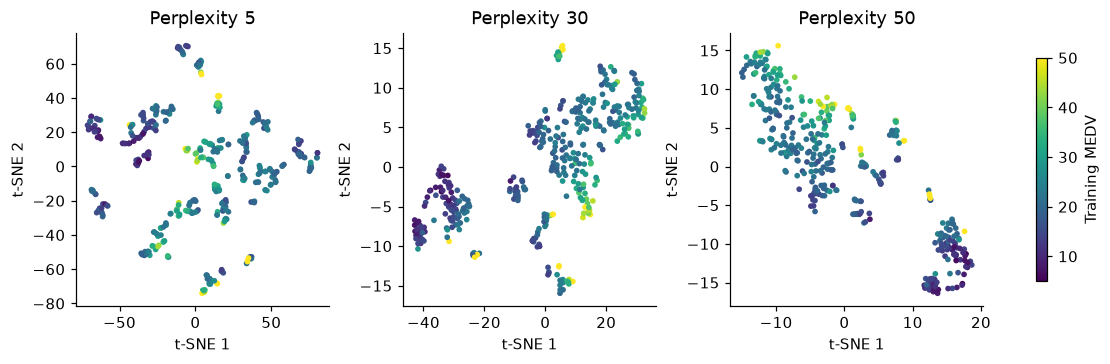

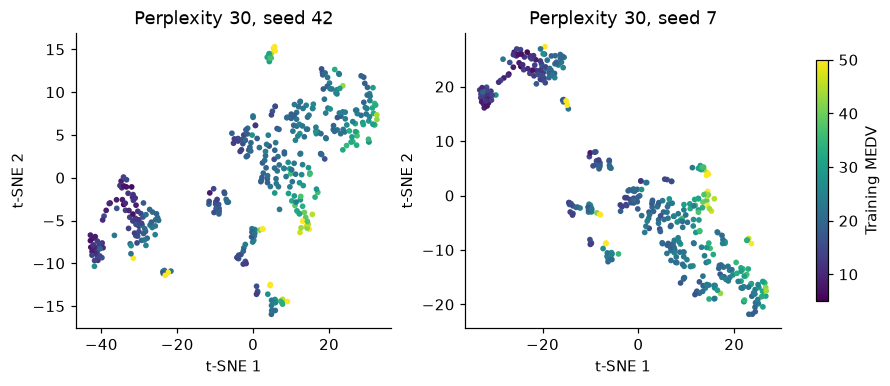

In [9]:
def plot_embeddings(panels, shape, size):
    fig, axes = plt.subplots(*shape, figsize=size, squeeze=False,
                             layout="constrained")
    for ax, (title, points, xlabel, ylabel) in zip(axes.flat, panels):
        points_plot = ax.scatter(
            points[:, 0], points[:, 1], c=y_train, cmap="viridis",
            vmin=y_train.min(), vmax=y_train.max(), s=14, linewidths=0
        )
        ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    fig.colorbar(points_plot, ax=list(axes.flat), label="Training MEDV",
                 shrink=0.82)
    plt.show()

plot_embeddings(
    [("PCA training scores", train_scores,
      f"PC1 ({variance[0]:.1%})", f"PC2 ({variance[1]:.1%})")],
    (1, 1), (6.0, 3.8)
)

perplexities = [5, 30, 50]
assert max(perplexities) < len(train_scaled)

def embed_tsne(perplexity, random_seed):
    model = TSNE(
        n_components=2, perplexity=perplexity, init="random",
        learning_rate=200, early_exaggeration=12, max_iter=1000,
        metric="euclidean", method="barnes_hut", angle=0.5,
        random_state=random_seed, n_jobs=1
    )
    with threadpool_limits(limits=1):
        return model.fit_transform(train_scaled)

tsne = {p: embed_tsne(p, seed) for p in perplexities}
plot_embeddings(
    [(f"Perplexity {p}", tsne[p], "t-SNE 1", "t-SNE 2") for p in perplexities],
    (1, 3), (10, 3.2)
)
tsne_seed7 = embed_tsne(30, 7)
plot_embeddings(
    [("Perplexity 30, seed 42", tsne[30], "t-SNE 1", "t-SNE 2"),
     ("Perplexity 30, seed 7", tsne_seed7, "t-SNE 1", "t-SNE 2")],
    (1, 2), (8, 3.4)
)

## 9. Visualise UMAP

Use Euclidean distance, two components, seed 42, spectral initialisation, one worker, 500 epochs, spread 1, and the legacy layout explicitly selected with `compatibility_layout=True` in umap-learn 0.6. Compare 5, 15 and 50 neighbours at minimum distance 0.1. Isolate the minimum-distance effect at 15 neighbours by using the same 0.1 result for comparison with 0.5. UMAP and t-SNE are used for visual exploration.

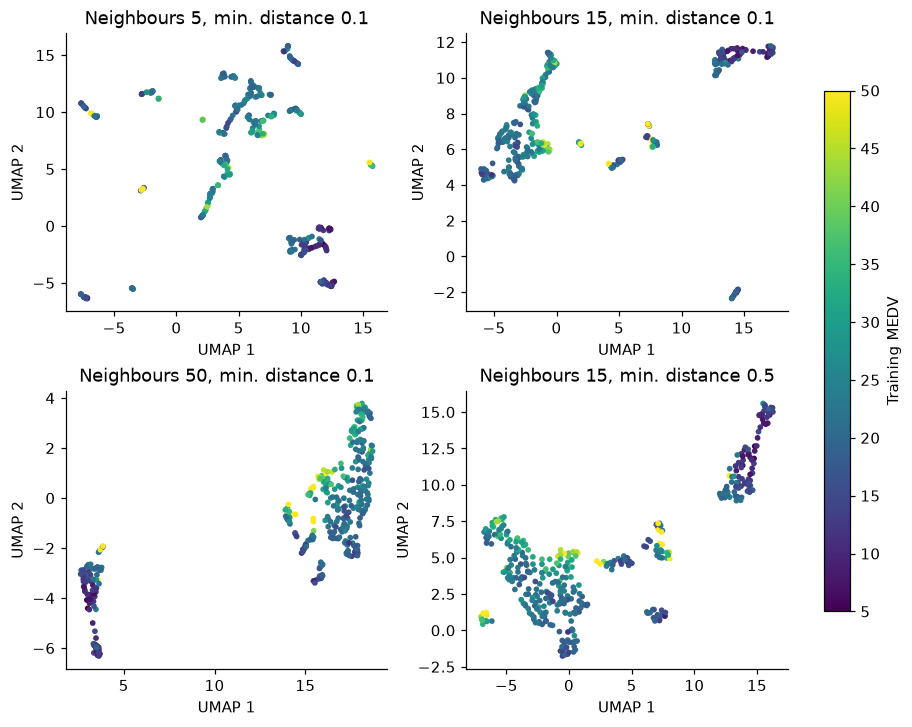

In [10]:
settings = [(5, 0.1), (15, 0.1), (50, 0.1), (15, 0.5)]
umap = {}
for neighbours, min_dist in settings:
    umap[neighbours, min_dist] = UMAP(
        n_components=2, n_neighbors=neighbours, min_dist=min_dist,
        metric="euclidean", init="spectral", spread=1.0, n_epochs=500,
        random_state=seed, n_jobs=1, compatibility_layout=True
    ).fit_transform(train_scaled)

plot_embeddings(
    [(f"Neighbours {n}, min. distance {d}", umap[n, d], "UMAP 1", "UMAP 2")
     for n, d in settings],
    (2, 2), (8.2, 6.5)
)

In [11]:
# Compare local target differences and seed stability by observation identity.
def neighbours_of(points):
    model = NearestNeighbors(n_neighbors=10).fit(points)
    return model.kneighbors(return_distance=False)

embeddings = {
    "Standardised predictors": train_scaled,
    "PCA (two axes)": train_scores[:, :2],
    **{f"t-SNE p={p}, seed 42": tsne[p] for p in perplexities},
    "t-SNE p=30, seed 7": tsne_seed7,
    **{f"UMAP n={n}, d={d}": umap[n, d] for n, d in settings},
}
near = {name: neighbours_of(points) for name, points in embeddings.items()}
target_values = y_train.to_numpy()
gaps = {name: np.abs(target_values[:, None] - target_values[idx]).mean()
        for name, idx in near.items()}
original = near["Standardised predictors"]
anchor = np.median(target_values[original], axis=1).argmin()
original_neighbours = original[anchor]
kept = {name: len(np.intersect1d(original_neighbours, indices[anchor]))
        for name, indices in near.items()}
display(pd.DataFrame({"Mean absolute MEDV gap": gaps,
                      "Anchor neighbours retained (of 10)": kept}).round(3))
profile = train_imputed[np.r_[anchor, original_neighbours]]
print(f"Low-MEDV anchor is data row {X_train.index[anchor] + 1} (header excluded).")
display(pd.DataFrame([np.median(profile, axis=0), np.median(train_imputed, axis=0)],
                     index=["Anchor and 10 original neighbours", "Training set"],
                     columns=features)[["RM", "LSTAT"]].round(2))
print("Neighbourhood median MEDV:",
      round(np.median(target_values[np.r_[anchor, original_neighbours]]), 2))
a, b = near["t-SNE p=30, seed 42"], near["t-SNE p=30, seed 7"]
seed_overlap = np.mean([len(set(x) & set(z)) / 10 for x, z in zip(a, b)])
print(f"Mean 10-neighbour overlap across t-SNE seeds: {seed_overlap:.1%}")

,Mean absolute MEDV gap,Anchor neighbours retained (of 10)
Standardised predictors,4.496,10
PCA (two axes),5.392,6
"t-SNE p=5, seed 42",5.279,5
"t-SNE p=30, seed 42",4.815,5
"t-SNE p=50, seed 42",4.917,6
"t-SNE p=30, seed 7",5.061,4
"UMAP n=5, d=0.1",5.520,5
"UMAP n=15, d=0.1",5.251,6
"UMAP n=50, d=0.1",5.039,3
"UMAP n=15, d=0.5",5.126,7


Low-MEDV anchor is data row 411 (header excluded).


,RM,LSTAT
Anchor and 10 original neighbours,5.90,20.62
Training set,6.21,10.92


Neighbourhood median MEDV: 8.8
Mean 10-neighbour overlap across t-SNE seeds: 80.6%


## 10. Interpret results in Python and R

### Test performance and compression

The 13-input baseline led on all three test metrics with RMSE **3.005**, MAE **2.082**, and R² **0.877**. Lasso and Elastic Net increased RMSE by 0.072 and 0.024 MEDV units, respectively. Their observed-versus-predicted plots follow the baseline closely. Elastic Net had the lowest RMSE among the reduced pipelines on this split.

PCA retained **7 components** (46.2% fewer inputs) and explained **90.01%** of training predictor variance. Its RMSE rose to **4.255**. The PCA forest missed several high observed values by a wide margin. PCA preserves predictor variance and changes the directions available for the forest's splits, so even a high retained variance can give weaker predictions.

Lasso retained **8 predictors** (38.5% fewer) and Elastic Net retained **10 predictors** (23.1% fewer). Forest fitting took 0.809 s for the baseline and PCA 0.785 s, Lasso 0.841 s, Elastic Net 1.032 s. Only PCA was slightly quicker than the baseline in this run. These are single-run timings and the accuracy differences come from one holdout split.

### Selected predictors

Lasso at alpha 0.20 retained eight predictors. Elastic Net at alpha 0.55 and L1 ratio 0.5 retained those eight plus INDUS and TAX. INDUS correlated with NX (r = 0.77) and DIS (r = -0.71). TAX correlated with NX (r = 0.65) and DIS (r = -0.52). The L2 term allows correlated predictors to share weight, and the two fits also used different penalty strengths. The selectors produce column subsets, and the Random Forest generates the final predictions.

### Visual structure and sensitivity

Colours generally darken towards positive PC1, especially in the right-hand arm. Moderate and high MEDV values overlap more in the broader cloud. The two-axis PCA has an average absolute MEDV difference of 5.392 between neighbouring points, compared with 4.496 in the 13 standardised inputs.

For example, data row 411 and its ten nearest neighbours in the original standardised space had median MEDV 8.8. Their median RM was 5.90 and median LSTAT was 20.62, versus 6.21 and 10.92 in the training set. The anchor counts in Section 9 show how many of its original neighbours each embedding preserved.

The low-MEDV group remains visible across PCA, t-SNE and UMAP, although high values are interspersed with moderate ones. At perplexity 5, t-SNE breaks the sample into small islands. At 30 and 50, broader groups emerge. Changing the seed at 30 moves or rotates the groups, while the mean overlap of each point's ten nearest neighbours is **80.6%**.

UMAP shows smaller, more separated patches with 5 neighbours and broader groups with 50. At 15 neighbours, raising the minimum distance from 0.1 to 0.5 spreads out the denser patches while retaining the low-value region. Relative positions, group areas and gaps change with the settings. These plots describe the training predictors and do not establish predictive accuracy.

### Python and R comparison

| Pipeline | Python inputs | Python RMSE | R inputs | R RMSE |
|---|---:|---:|---:|---:|
| Baseline | 13 | 3.005 | 13 | 2.849 |
| PCA + RF | 7 | 4.255 | 8 | 4.201 |
| Lasso + RF | 8 | 3.077 | 8 | 2.952 |
| Elastic Net + RF | 10 | 3.029 | 9 | 2.944 |

Both runs rank the baseline first on RMSE, MAE and R². Elastic Net has the smallest RMSE increase among the reduced models, and PCA incurs the largest increase. The Lasso subsets match across languages. Both Elastic Net subsets add INDUS, and Python also retains TAX. PCA needs seven components in Python and eight in R to meet the same 90% rule. Both sets of embeddings show low-value neighbourhoods despite differences in layout. Each language generated its own training/test split using seed 42. The splits, random-number generators and implementations can all contribute to the numerical differences.

### Software versions

In [12]:
print("Python", platform.python_version())
for package in ["numpy", "pandas", "scikit-learn", "matplotlib",
                "umap-learn", "numba", "pynndescent", "threadpoolctl", "ipykernel"]:
    print(f"{package}: {version(package)}")

Python 3.12.15
numpy: 2.5.5
pandas: 3.1.1
scikit-learn: 1.9.1
matplotlib: 3.11.2
umap-learn: 0.6.0
numba: 0.68.1
pynndescent: 0.7.0
threadpoolctl: 3.8.0
ipykernel: 7.4.0
